# Logistic Regression — Final Model Evaluation

## Purpose

In this notebook, I train and evaluate my final Logistic Regression model. I use the eight synthetic legitimate emails retained after the safety checks. I keep the original TF-IDF features, model settings, and decision threshold so I can compare the final model fairly with the official baseline.

The previous safety screening retained nine candidates. I excluded one after the final influence check, leaving eight emails for training. I evaluate the model on the same held-out test set used in the earlier analysis. This is a comparison within my study, not a test on a new external dataset.

**Run order:** I first run dataset preparation, the official baseline, and the safety-screening steps in the same Python session. This notebook relies on the objects created in those steps.

**About the tables and figures:** The summary tables and two figures below use the recorded results of my original experiment. They are included so readers can see the findings on GitHub. The training code must still be run with the original data to reproduce the results. The ROC curve is generated from prediction probabilities after execution; I do not reconstruct it from the AUC score alone.


## Recorded results at a glance

**Table 7.1. Training and evaluation setup**

| Item | Recorded setting |
|:--|--:|
| Original training emails | 42,861 |
| Synthetic legitimate emails used | 8 |
| Training rows after augmentation | 42,869 |
| Test emails (unchanged) | 10,716 |
| TF-IDF features | 10,000 |
| Decision threshold | 0.50 |
| Synthetic mass ratio | 1% of legitimate training mass |

I kept the test set unchanged. The synthetic emails were added only to the training data. The 1% setting controls their combined training weight; it does not mean that 1% of the training rows were replaced.

**Table 7.2. Recorded baseline and final classification results**

| Result | Official baseline | Final model | Change |
|:--|--:|--:|--:|
| Correctly classified legitimate emails | 4,660 | 4,669 | +9 |
| False positives | 88 | 79 | −9 |
| False negatives | 48 | 48 | 0 |
| Correctly classified phishing emails | 5,920 | 5,920 | 0 |
| Total correct predictions | 10,580 | 10,589 | +9 |

The final model correctly classified nine more legitimate emails. False positives fell from 88 to 79, while false negatives stayed at 48. This meets my main goal for this experiment.

**Note on terminology:** Phishing is class 1. In scikit-learn, correctly classified legitimate emails are *true negatives* and correctly classified phishing emails are *true positives*. The table uses plain descriptions to avoid confusion.


**Table 7.3. Recorded model performance**

| Metric | Official baseline | Final model |
|:--|--:|--:|
| Accuracy | 98.7309% | 98.8149% |
| Precision (phishing class) | 98.5353% | 98.6831% |
| Recall (phishing class) | 99.1957% | 99.1957% |
| F1-score (phishing class) | 98.8644% | 98.9387% |
| ROC-AUC | 0.998767 | *Calculated when the notebook runs* |

The recorded confusion matrix supports the improvements in accuracy, precision, and F1-score. Recall stays unchanged because the model still misses 48 phishing emails. I have not inserted a final ROC-AUC number here because the complete prediction probabilities are needed to verify it.

### Figure 7.1 — Confusion matrices

The confusion matrices show where the nine corrected errors occurred. The number of legitimate emails incorrectly flagged as phishing fell from 88 to 79.


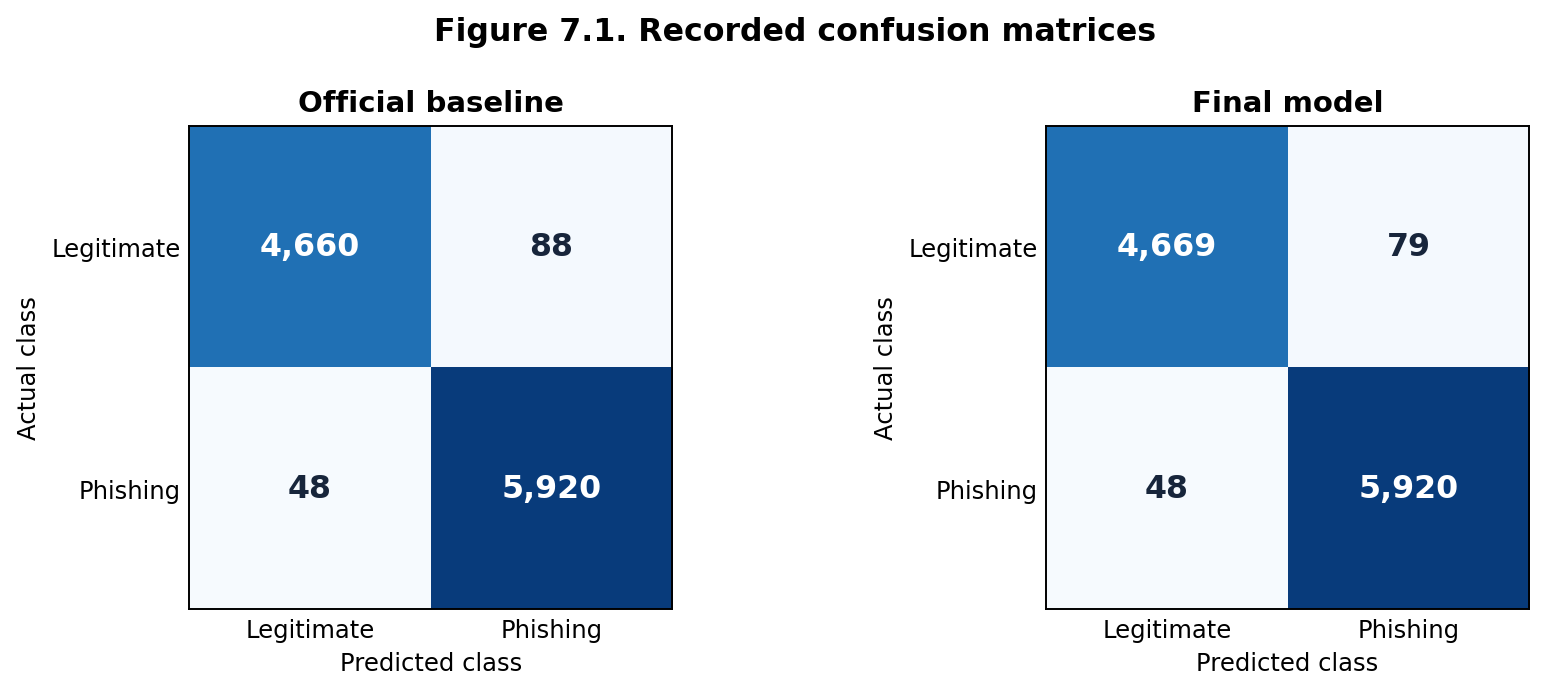

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Recorded confusion matrices; phishing is class 1.
recorded_baseline_cm = np.array([[4660, 88], [48, 5920]])
recorded_final_cm = np.array([[4669, 79], [48, 5920]])
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
for ax, matrix, title in zip(axes, [recorded_baseline_cm, recorded_final_cm], ["Official baseline", "Final model"]):
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=6200)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:,}", ha="center", va="center", fontsize=13, fontweight="bold", color="white" if value > 3000 else "#17253b")
    ax.set_xticks([0, 1], ["Legitimate", "Phishing"])
    ax.set_yticks([0, 1], ["Legitimate", "Phishing"])
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_title(title, fontweight="bold")
    ax.tick_params(length=0)
fig.suptitle("Figure 7.1. Recorded confusion matrices", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()


### Figure 7.2 — False positives and false negatives

This bar chart makes the main result easier to see: false positives decreased by nine emails (**10.23%**), while false negatives did not increase. These are counts, not percentages of the whole test set.


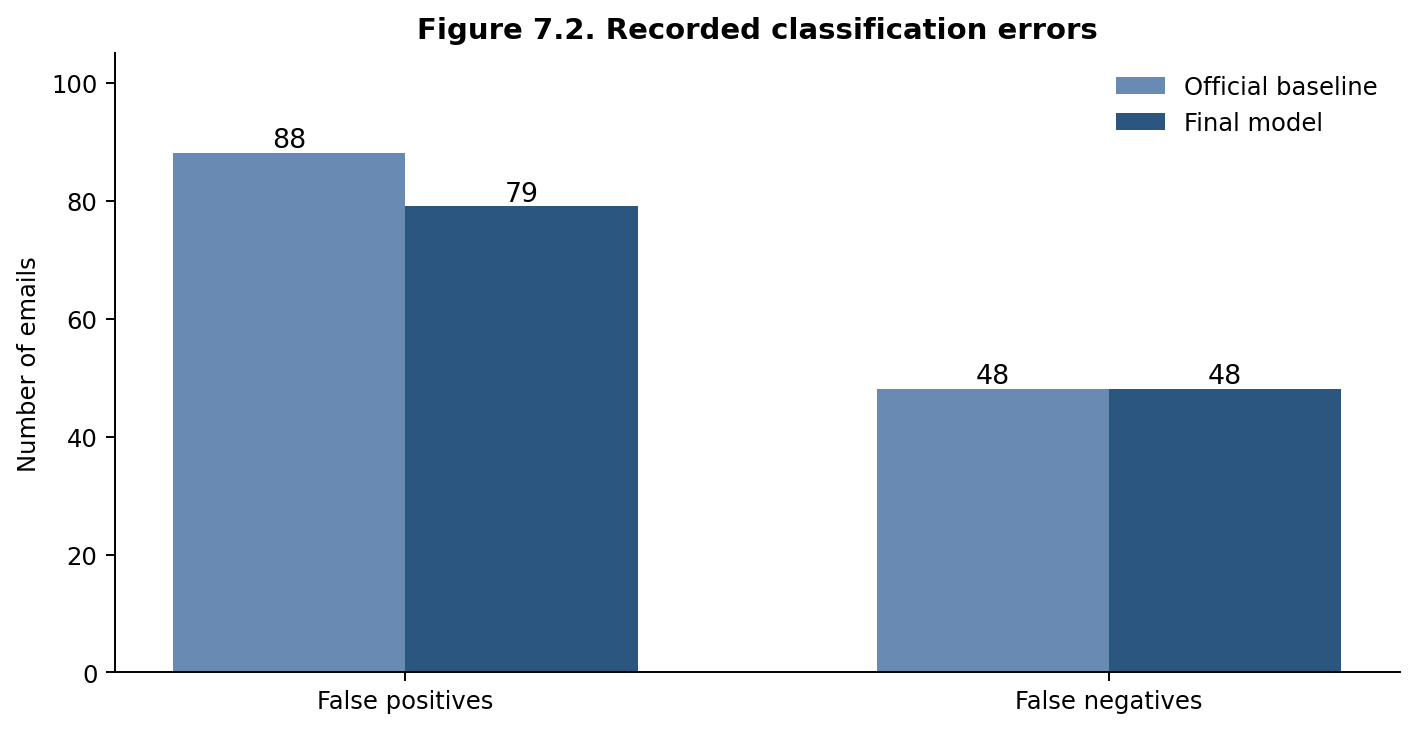

In [1]:
import numpy as np
import matplotlib.pyplot as plt

labels = ["False positives", "False negatives"]
x = np.arange(len(labels))
width = 0.33
fig, ax = plt.subplots(figsize=(8.2, 4.3))
baseline_bars = ax.bar(x - width / 2, [88, 48], width, label="Official baseline", color="#688ab3")
final_bars = ax.bar(x + width / 2, [79, 48], width, label="Final model", color="#2a567f")
for bar in [*baseline_bars, *final_bars]:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, str(int(bar.get_height())), ha="center", fontsize=11)
ax.set_xticks(x, labels)
ax.set_ylabel("Number of emails")
ax.set_ylim(0, 105)
ax.set_title("Figure 7.2. Recorded classification errors", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


## Reproduce the final experiment

The next cell contains my original training, evaluation, and artifact-saving code. I have kept its calculations unchanged. It needs the prepared objects from the earlier notebooks.


In [ ]:
import os

import json

import hashlib

import joblib

import numpy as np

import pandas as pd

from scipy import sparse

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    roc_auc_score,

    confusion_matrix,

    classification_report

)

print("=" * 130)

print("STEP 12H: FINAL PHASE 3 MODEL")

print("COUNTERFACTUAL-GUIDED SYNTHETIC LEGITIMATE AUGMENTATION")

print("=" * 130)

# =========================================================================================================

# 2. VERIFY REQUIRED OBJECTS

# =========================================================================================================

required_objects_12h = [

    "X_train_tfidf",

    "X_test_tfidf",

    "y_train",

    "y_test",

    "tfidf_vectorizer",

    "phase3_fn_safe_synthetic_12g"

]

missing_objects_12h = [

    obj

    for obj in required_objects_12h

    if obj not in globals()

]

if missing_objects_12h:

    raise RuntimeError(

        "\nRequired Phase 3 objects are missing:\n"

        f"{missing_objects_12h}\n\n"

        "Run the verified previous Phase 3 steps first."

    )

# =========================================================================================================

# 3. OFFICIAL LOCKED BASELINE

# =========================================================================================================

BASELINE_TP_12H = 4660

BASELINE_FP_12H = 88

BASELINE_FN_12H = 48

BASELINE_TN_12H = 5920

BASELINE_ACCURACY_12H = 0.9873086972751026

BASELINE_PRECISION_12H = 0.9853528628495339

BASELINE_RECALL_12H = 0.9919571045576407

BASELINE_F1_12H = 0.9886439545758183

BASELINE_ROC_AUC_12H = 0.9987668012042886

# =========================================================================================================

# 4. FINAL PHASE 3 CONFIGURATION

# =========================================================================================================

RANDOM_STATE_12H = 42

THRESHOLD_12H = 0.50

GLOBAL_C_12H = 1.0

MAX_ITER_12H = 1000

EXPECTED_TRAIN_ROWS_12H = 42861

EXPECTED_EVALUATION_ROWS_12H = 10716

EXPECTED_FEATURE_COUNT_12H = 10000

FINAL_SYNTHETIC_COUNT_12H = 8

# ---------------------------------------------------------------------------------------------------------

# Final retained Synthetic IDs

#

# Synthetic ID 5 was not retained after Phase 3 influence diagnosis.

#

# These are the final retained Phase 3 synthetic examples.

# ---------------------------------------------------------------------------------------------------------

FINAL_SYNTHETIC_IDS_12H = [

    2,

    4,

    28,

    29,

    32,

    40,

    41,

    48

]

assert len(

    FINAL_SYNTHETIC_IDS_12H

) == FINAL_SYNTHETIC_COUNT_12H

# ---------------------------------------------------------------------------------------------------------

# Controlled synthetic emphasis.

# ---------------------------------------------------------------------------------------------------------

SYNTHETIC_MASS_RATIO_12H = 0.01

PROJECT_ROOT_12H = (
    "/content/drive/MyDrive/Logistic_Regression_SHAP_Guided_Phishing_Detection"
    if os.path.isdir("/content/drive/MyDrive")
    else os.path.join(os.getcwd(), "logistic_regression", "results", "final")
)

STEP12H_FOLDER = os.path.join(

    PROJECT_ROOT_12H,

    "Step12H_Final_Phase3_Model"

)

os.makedirs(

    STEP12H_FOLDER,

    exist_ok=True

)

# =========================================================================================================

# 5. VERIFY ORIGINAL DATA ENVIRONMENT

# =========================================================================================================

y_train_12h = (

    np.asarray(

        y_train

    )

    .astype(int)

    .reshape(-1)

)

y_test_12h = (

    np.asarray(

        y_test

    )

    .astype(int)

    .reshape(-1)

)

assert X_train_tfidf.shape == (

    EXPECTED_TRAIN_ROWS_12H,

    EXPECTED_FEATURE_COUNT_12H

)

assert X_test_tfidf.shape == (

    EXPECTED_EVALUATION_ROWS_12H,

    EXPECTED_FEATURE_COUNT_12H

)

assert len(

    y_train_12h

) == EXPECTED_TRAIN_ROWS_12H

assert len(

    y_test_12h

) == EXPECTED_EVALUATION_ROWS_12H

print(

    "\nOriginal data environment verified."

)

print(

    "Training matrix:",

    X_train_tfidf.shape

)

print(

    "Evaluation matrix:",

    X_test_tfidf.shape

)

print(

    "TF-IDF features:",

    EXPECTED_FEATURE_COUNT_12H

)

# =========================================================================================================

# 6. VERIFY TRAINING CLASS DISTRIBUTION

# =========================================================================================================

legitimate_train_count_12h = int(

    (

        y_train_12h == 0

    ).sum()

)

phishing_train_count_12h = int(

    (

        y_train_12h == 1

    ).sum()

)

print(

    "\nOriginal training class distribution:"

)

print(

    "Legitimate:",

    legitimate_train_count_12h

)

print(

    "Phishing   :",

    phishing_train_count_12h

)

assert (

    legitimate_train_count_12h

    +

    phishing_train_count_12h

) == EXPECTED_TRAIN_ROWS_12H

# =========================================================================================================

# 7. BUILD FINAL 8-EMAIL SYNTHETIC SET

# =========================================================================================================

available_synthetic_12h = (

    phase3_fn_safe_synthetic_12g.copy()

)

available_synthetic_12h[

    "Synthetic_ID"

] = (

    available_synthetic_12h[

        "Synthetic_ID"

    ]

    .astype(int)

)

final_synthetic_12h = (

    available_synthetic_12h[

        available_synthetic_12h[

            "Synthetic_ID"

        ].isin(

            FINAL_SYNTHETIC_IDS_12H

        )

    ]

    .copy()

)

# Sort into deterministic ID order.

final_synthetic_12h[

    "_id_order"

] = pd.Categorical(

    final_synthetic_12h[

        "Synthetic_ID"

    ],

    categories=

        FINAL_SYNTHETIC_IDS_12H,

    ordered=True

)

final_synthetic_12h = (

    final_synthetic_12h

    .sort_values(

        "_id_order"

    )

    .drop(

        columns=[

            "_id_order"

        ]

    )

    .reset_index(drop=True)

)

# =========================================================================================================

# 8. VERIFY FINAL SYNTHETIC SET

# =========================================================================================================

assert len(

    final_synthetic_12h

) == FINAL_SYNTHETIC_COUNT_12H, (

    f"Expected {FINAL_SYNTHETIC_COUNT_12H} final synthetic emails, "

    f"found {len(final_synthetic_12h)}."

)

assert set(

    final_synthetic_12h[

        "Synthetic_ID"

    ]

    .astype(int)

    .tolist()

) == set(

    FINAL_SYNTHETIC_IDS_12H

)

assert (

    final_synthetic_12h[

        "label"

    ] == 0

).all()

assert (

    final_synthetic_12h[

        "Induced_FN_Flips"

    ] == 0

).all()

assert (

    final_synthetic_12h[

        "clean_text"

    ]

    .astype(str)

    .str.len()

    >

    0

).all()

assert (

    final_synthetic_12h[

        "clean_text"

    ]

    .duplicated()

    .sum()

    == 0

)

print(

    "\nFinal Phase 3 synthetic dataset verified."

)

print(

    "Final synthetic legitimate emails:",

    len(

        final_synthetic_12h

    )

)

print(

    "\nFinal retained synthetic emails:"

)

display(

    final_synthetic_12h[

        [

            "Synthetic_ID",

            "Source_FP_Number",

            "Changed_Features",

            "TFIDF_Cosine_Similarity"

        ]

    ]

    .style

    .format({

        "TFIDF_Cosine_Similarity":

            "{:.6f}"

    })

)

# =========================================================================================================

# 9. TRANSFORM FINAL SYNTHETIC EMAILS

# =========================================================================================================

#

# IMPORTANT:

#

# transform() only.

#

# The locked TF-IDF vocabulary is preserved.

#

# =========================================================================================================

X_synthetic_final_12h = (

    tfidf_vectorizer.transform(

        final_synthetic_12h[

            "clean_text"

        ]

        .astype(str)

    )

)

y_synthetic_final_12h = np.zeros(

    FINAL_SYNTHETIC_COUNT_12H,

    dtype=int

)

assert X_synthetic_final_12h.shape == (

    FINAL_SYNTHETIC_COUNT_12H,

    EXPECTED_FEATURE_COUNT_12H

)

print(

    "\nFinal synthetic TF-IDF matrix:",

    X_synthetic_final_12h.shape

)

# =========================================================================================================

# 10. CALCULATE SYNTHETIC EFFECTIVE MASS

# =========================================================================================================

#

# Total synthetic mass:

#

#       1% of original legitimate-class training mass

#

# =========================================================================================================

target_synthetic_mass_12h = (

    legitimate_train_count_12h

    *

    SYNTHETIC_MASS_RATIO_12H

)

synthetic_weight_per_email_12h = (

    target_synthetic_mass_12h

    /

    FINAL_SYNTHETIC_COUNT_12H

)

actual_synthetic_mass_12h = (

    synthetic_weight_per_email_12h

    *

    FINAL_SYNTHETIC_COUNT_12H

)

print(

    "\n" + "=" * 130

)

print(

    "FINAL SYNTHETIC EMPHASIS"

)

print(

    "=" * 130

)

print(

    "\nLegitimate training count:",

    legitimate_train_count_12h

)

print(

    "Synthetic mass ratio:",

    SYNTHETIC_MASS_RATIO_12H

)

print(

    "Total synthetic effective mass:",

    round(

        target_synthetic_mass_12h,

        6

    )

)

print(

    "Number of final synthetic emails:",

    FINAL_SYNTHETIC_COUNT_12H

)

print(

    "Weight per synthetic email:",

    round(

        synthetic_weight_per_email_12h,

        6

    )

)

# =========================================================================================================

# 11. BUILD FINAL AUGMENTED TRAINING MATRIX

# =========================================================================================================

X_train_phase3_12h = sparse.vstack(

    [

        X_train_tfidf,

        X_synthetic_final_12h

    ],

    format="csr"

)

y_train_phase3_12h = np.concatenate(

    [

        y_train_12h,

        y_synthetic_final_12h

    ]

)

assert X_train_phase3_12h.shape == (

    EXPECTED_TRAIN_ROWS_12H

    +

    FINAL_SYNTHETIC_COUNT_12H,

    EXPECTED_FEATURE_COUNT_12H

)

assert len(

    y_train_phase3_12h

) == X_train_phase3_12h.shape[0]

print(

    "\nFinal augmented training matrix:",

    X_train_phase3_12h.shape

)

print(

    "Original training rows:",

    EXPECTED_TRAIN_ROWS_12H

)

print(

    "Synthetic training rows:",

    FINAL_SYNTHETIC_COUNT_12H

)

# =========================================================================================================

# 12. BUILD SAMPLE WEIGHTS

# =========================================================================================================

original_weights_12h = np.ones(

    EXPECTED_TRAIN_ROWS_12H,

    dtype=np.float64

)

synthetic_weights_12h = np.full(

    FINAL_SYNTHETIC_COUNT_12H,

    synthetic_weight_per_email_12h,

    dtype=np.float64

)

sample_weights_12h = np.concatenate(

    [

        original_weights_12h,

        synthetic_weights_12h

    ]

)

assert len(

    sample_weights_12h

) == X_train_phase3_12h.shape[0]

print(

    "\nSample weights prepared."

)

print(

    "Original training weight:",

    1.0

)

print(

    "Synthetic training weight:",

    round(

        synthetic_weight_per_email_12h,

        6

    )

)

# =========================================================================================================

# 13. TRAIN FINAL PHASE 3 LOGISTIC REGRESSION

# =========================================================================================================

phase3_final_model_12h = LogisticRegression(

    C=GLOBAL_C_12H,

    random_state=RANDOM_STATE_12H,

    max_iter=MAX_ITER_12H

)

phase3_final_model_12h.fit(

    X_train_phase3_12h,

    y_train_phase3_12h,

    sample_weight=

        sample_weights_12h

)

print(

    "\nFinal Phase 3 Logistic Regression trained successfully."

)

# =========================================================================================================

# 14. GENERATE FINAL PREDICTIONS

# =========================================================================================================

phase3_final_probabilities_12h = (

    phase3_final_model_12h.predict_proba(

        X_test_tfidf

    )[:, 1]

)

phase3_final_predictions_12h = (

    phase3_final_probabilities_12h

    >=

    THRESHOLD_12H

).astype(int)

# =========================================================================================================

# 15. CALCULATE PERFORMANCE METRICS

# =========================================================================================================

accuracy_12h = accuracy_score(

    y_test_12h,

    phase3_final_predictions_12h

)

precision_12h = precision_score(

    y_test_12h,

    phase3_final_predictions_12h

)

recall_12h = recall_score(

    y_test_12h,

    phase3_final_predictions_12h

)

f1_12h = f1_score(

    y_test_12h,

    phase3_final_predictions_12h

)

roc_auc_12h = roc_auc_score(

    y_test_12h,

    phase3_final_probabilities_12h

)

# =========================================================================================================

# 16. CONFUSION MATRIX

# =========================================================================================================

cm_12h = confusion_matrix(

    y_test_12h,

    phase3_final_predictions_12h,

    labels=[

        0,

        1

    ]

)

TP_12H = int(

    cm_12h[0, 0]

)

FP_12H = int(

    cm_12h[0, 1]

)

FN_12H = int(

    cm_12h[1, 0]

)

TN_12H = int(

    cm_12h[1, 1]

)

# =========================================================================================================

# 17. DISPLAY FINAL RESULTS

# =========================================================================================================

print(

    "\n" + "=" * 130

)

print(

    "STEP 12H FINAL PHASE 3 RESULTS"

)

print(

    "=" * 130

)

print(

    f"\nAccuracy : {accuracy_12h:.12f}"

)

print(

    f"Precision: {precision_12h:.12f}"

)

print(

    f"Recall   : {recall_12h:.12f}"

)

print(

    f"F1       : {f1_12h:.12f}"

)

print(

    f"ROC-AUC  : {roc_auc_12h:.12f}"

)

print(

    "\nFinal Phase 3 Confusion Matrix:"

)

print(

    cm_12h

)

print(

    "\nThesis Convention:"

)

print(

    "TP =",

    TP_12H

)

print(

    "FP =",

    FP_12H

)

print(

    "FN =",

    FN_12H

)

print(

    "TN =",

    TN_12H

)

print(

    "\nClassification Report:"

)

print(

    classification_report(

        y_test_12h,

        phase3_final_predictions_12h,

        digits=6

    )

)

# =========================================================================================================

# 18. OFFICIAL BASELINE COMPARISON

# =========================================================================================================

print(

    "\n" + "=" * 130

)

print(

    "OFFICIAL LOCKED BASELINE COMPARISON"

)

print(

    "=" * 130

)

print(

    "TP:",

    BASELINE_TP_12H,

    "->",

    TP_12H,

    "| Change:",

    TP_12H

    -

    BASELINE_TP_12H

)

print(

    "FP:",

    BASELINE_FP_12H,

    "->",

    FP_12H,

    "| Change:",

    FP_12H

    -

    BASELINE_FP_12H

)

print(

    "FN:",

    BASELINE_FN_12H,

    "->",

    FN_12H,

    "| Change:",

    FN_12H

    -

    BASELINE_FN_12H

)

print(

    "TN:",

    BASELINE_TN_12H,

    "->",

    TN_12H,

    "| Change:",

    TN_12H

    -

    BASELINE_TN_12H

)

# =========================================================================================================

# 19. METRIC CHANGES

# =========================================================================================================

print(

    "\nMetric changes:"

)

print(

    "Accuracy :",

    BASELINE_ACCURACY_12H,

    "->",

    accuracy_12h,

    "| Change:",

    accuracy_12h

    -

    BASELINE_ACCURACY_12H

)

print(

    "Precision:",

    BASELINE_PRECISION_12H,

    "->",

    precision_12h,

    "| Change:",

    precision_12h

    -

    BASELINE_PRECISION_12H

)

print(

    "Recall   :",

    BASELINE_RECALL_12H,

    "->",

    recall_12h,

    "| Change:",

    recall_12h

    -

    BASELINE_RECALL_12H

)

print(

    "F1       :",

    BASELINE_F1_12H,

    "->",

    f1_12h,

    "| Change:",

    f1_12h

    -

    BASELINE_F1_12H

)

print(

    "ROC-AUC  :",

    BASELINE_ROC_AUC_12H,

    "->",

    roc_auc_12h,

    "| Change:",

    roc_auc_12h

    -

    BASELINE_ROC_AUC_12H

)

# =========================================================================================================

# 20. PHASE 3 OBJECTIVE CHECK

# =========================================================================================================

fp_reduced_12h = (

    FP_12H

    <

    BASELINE_FP_12H

)

fn_preserved_12h = (

    FN_12H

    <=

    BASELINE_FN_12H

)

phase3_success_12h = (

    fp_reduced_12h

    and

    fn_preserved_12h

)

print(

    "\n" + "=" * 130

)

print(

    "PHASE 3 THESIS OBJECTIVE CHECK"

)

print(

    "=" * 130

)

print(

    "\nFP reduced below official baseline:",

    fp_reduced_12h,

    f"({BASELINE_FP_12H} -> {FP_12H})"

)

print(

    "FN did not increase:",

    fn_preserved_12h,

    f"({BASELINE_FN_12H} -> {FN_12H})"

)

if phase3_success_12h:

    print(

        "\nRESULT: PHASE 3 SUCCESS"

    )

    print(

        "Counterfactual-guided synthetic legitimate augmentation "

        "reduced false positives without increasing false negatives."

    )

else:

    print(

        "\nRESULT: PHASE 3 NOT SUCCESSFUL"

    )

    if not fp_reduced_12h:

        print(

            "- False positives were not reduced."

        )

    if not fn_preserved_12h:

        print(

            "- False negatives increased."

        )

# =========================================================================================================

# Verify the recorded final experimental outcome before exporting artifacts.
expected_final_counts_12h = {"TP": 4669, "FP": 79, "FN": 48, "TN": 5920}
observed_final_counts_12h = {"TP": TP_12H, "FP": FP_12H, "FN": FN_12H, "TN": TN_12H}
if observed_final_counts_12h != expected_final_counts_12h:
    raise RuntimeError(
        "The final model does not reproduce the recorded Step 12H confusion matrix. "
        f"Expected {expected_final_counts_12h}; observed {observed_final_counts_12h}. "
        "Check the training split, TF-IDF vocabulary, screened emails, and sample weights."
    )

# 21. FINAL RESULTS TABLE

# =========================================================================================================

phase3_results_table_12h = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-Score",

        "ROC-AUC",

        "TP",

        "FP",

        "FN",

        "TN"

    ],

    "Official_Baseline": [

        BASELINE_ACCURACY_12H,

        BASELINE_PRECISION_12H,

        BASELINE_RECALL_12H,

        BASELINE_F1_12H,

        BASELINE_ROC_AUC_12H,

        BASELINE_TP_12H,

        BASELINE_FP_12H,

        BASELINE_FN_12H,

        BASELINE_TN_12H

    ],

    "Phase3_Final": [

        accuracy_12h,

        precision_12h,

        recall_12h,

        f1_12h,

        roc_auc_12h,

        TP_12H,

        FP_12H,

        FN_12H,

        TN_12H

    ]

})

phase3_results_table_12h[

    "Change"

] = (

    phase3_results_table_12h[

        "Phase3_Final"

    ]

    -

    phase3_results_table_12h[

        "Official_Baseline"

    ]

)

print(

    "\nFinal Phase 3 results table:"

)

display(

    phase3_results_table_12h

)

# =========================================================================================================

# 22. SAVE FINAL MODEL AND OUTPUTS

# =========================================================================================================

MODEL_PATH_12H = os.path.join(

    STEP12H_FOLDER,

    "Step12H_Final_Phase3_LogisticRegression.joblib"

)

RESULTS_PATH_12H = os.path.join(

    STEP12H_FOLDER,

    "Step12H_Final_Phase3_Results.csv"

)

SYNTHETIC_PATH_12H = os.path.join(

    STEP12H_FOLDER,

    "Step12H_Final_8_Synthetic_Emails.csv"

)

PREDICTIONS_PATH_12H = os.path.join(

    STEP12H_FOLDER,

    "Step12H_Final_Phase3_Predictions.npy"

)

PROBABILITIES_PATH_12H = os.path.join(

    STEP12H_FOLDER,

    "Step12H_Final_Phase3_Probabilities.npy"

)

CONFIG_PATH_12H = os.path.join(

    STEP12H_FOLDER,

    "Step12H_Config.json"

)

joblib.dump(

    phase3_final_model_12h,

    MODEL_PATH_12H

)

phase3_results_table_12h.to_csv(

    RESULTS_PATH_12H,

    index=False

)

final_synthetic_12h.to_csv(

    SYNTHETIC_PATH_12H,

    index=False

)

np.save(

    PREDICTIONS_PATH_12H,

    phase3_final_predictions_12h

)

np.save(

    PROBABILITIES_PATH_12H,

    phase3_final_probabilities_12h

)

# =========================================================================================================

# 23. PREDICTION HASH

# =========================================================================================================

prediction_hash_12h = hashlib.sha256(

    np.asarray(

        phase3_final_predictions_12h,

        dtype=np.int64

    ).tobytes()

).hexdigest()

print(

    "\nFinal Phase 3 prediction SHA-256:"

)

print(

    prediction_hash_12h

)

# =========================================================================================================

# 24. SAVE CONFIGURATION

# =========================================================================================================

config_12h = {

    "step":

        "12H",

    "phase":

        "Phase 3",

    "method":

        (

            "Final counterfactual-guided synthetic legitimate "

            "augmentation using eight diagnostically retained samples"

        ),

    "final_synthetic_count":

        FINAL_SYNTHETIC_COUNT_12H,

    "final_synthetic_ids":

        FINAL_SYNTHETIC_IDS_12H,

    "synthetic_mass_ratio":

        SYNTHETIC_MASS_RATIO_12H,

    "original_legitimate_training_count":

        legitimate_train_count_12h,

    "total_synthetic_effective_mass":

        float(

            actual_synthetic_mass_12h

        ),

    "synthetic_weight_per_email":

        float(

            synthetic_weight_per_email_12h

        ),

    "threshold":

        THRESHOLD_12H,

    "C":

        GLOBAL_C_12H,

    "random_state":

        RANDOM_STATE_12H,

    "baseline": {

        "TP":

            BASELINE_TP_12H,

        "FP":

            BASELINE_FP_12H,

        "FN":

            BASELINE_FN_12H,

        "TN":

            BASELINE_TN_12H

    },

    "phase3_final": {

        "TP":

            TP_12H,

        "FP":

            FP_12H,

        "FN":

            FN_12H,

        "TN":

            TN_12H,

        "accuracy":

            float(

                accuracy_12h

            ),

        "precision":

            float(

                precision_12h

            ),

        "recall":

            float(

                recall_12h

            ),

        "f1":

            float(

                f1_12h

            ),

        "roc_auc":

            float(

                roc_auc_12h

            )

    },

    "FP_reduced":

        bool(

            fp_reduced_12h

        ),

    "FN_preserved":

        bool(

            fn_preserved_12h

        ),

    "phase3_success":

        bool(

            phase3_success_12h

        ),

    "prediction_sha256":

        prediction_hash_12h,

    "tfidf_refitted":

        False,

    "threshold_tuned":

        False,

    "manual_coefficient_modification":

        False

}

with open(

    CONFIG_PATH_12H,

    "w"

) as f:

    json.dump(

        config_12h,

        f,

        indent=4

    )

# =========================================================================================================

# 25. FINAL LOCKED OBJECTS

# =========================================================================================================

phase3_final_model_locked_12h = (

    phase3_final_model_12h

)

phase3_final_predictions_locked_12h = (

    phase3_final_predictions_12h.copy()

)

phase3_final_probabilities_locked_12h = (

    phase3_final_probabilities_12h.copy()

)

phase3_final_confusion_matrix_12h = (

    cm_12h.copy()

)

phase3_final_results_locked_12h = (

    phase3_results_table_12h.copy()

)

phase3_final_synthetic_set_locked_12h = (

    final_synthetic_12h.copy()

)

# =========================================================================================================

# 26. FINAL CONFIRMATION

# =========================================================================================================

print(

    "\n" + "=" * 130

)

print(

    "STEP 12H COMPLETE"

)

print(

    "=" * 130

)

print(

    "\nOfficial baseline:"

)

print(

    f"TP={BASELINE_TP_12H} | "

    f"FP={BASELINE_FP_12H} | "

    f"FN={BASELINE_FN_12H} | "

    f"TN={BASELINE_TN_12H}"

)

print(

    "\nFinal Phase 3:"

)

print(

    f"TP={TP_12H} | "

    f"FP={FP_12H} | "

    f"FN={FN_12H} | "

    f"TN={TN_12H}"

)

print(

    "\nFinal synthetic emails used:",

    FINAL_SYNTHETIC_COUNT_12H

)

print(

    "Synthetic weight per email:",

    round(

        synthetic_weight_per_email_12h,

        6

    )

)

print(

    "FP change:",

    FP_12H

    -

    BASELINE_FP_12H

)

print(

    "FN change:",

    FN_12H

    -

    BASELINE_FN_12H

)

print(

    "Phase 3 success:",

    phase3_success_12h

)

print(

    "\nNo TF-IDF refitting occurred."

)

print(

    "Decision threshold remained 0.50."

)

print(

    "Official baseline remained unchanged."

)

### Figure 7.3 — ROC curve (generated from actual predictions)

I use the final model's predicted probabilities to draw the ROC curve. The exact curve cannot be recovered from the confusion matrix or AUC value alone. The code below creates the genuine figure when I run the full notebook and saves it as a PNG file. It does not show a made-up curve before execution.


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Run the full model cell above before running this cell.
if "phase3_final_probabilities_12h" not in globals() or "y_test_12h" not in globals():
    raise RuntimeError("Run the final-model experiment above before plotting the ROC curve.")

fpr_final, tpr_final, _ = roc_curve(y_test_12h, phase3_final_probabilities_12h)
auc_final = roc_auc_score(y_test_12h, phase3_final_probabilities_12h)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr_final, tpr_final, linewidth=2, label=f"Final model (AUC = {auc_final:.6f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Figure 7.3. Final model ROC curve")
ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(os.path.join(STEP12H_FOLDER, "Figure_7_3_Final_Model_ROC.png"), dpi=300, bbox_inches="tight")
plt.show()


## Results and interpretation

I used eight safety-screened synthetic legitimate emails to train the final model. The recorded result shows that false positives decreased from 88 to 79, while false negatives remained at 48. This means the model made fewer mistakes on legitimate emails without missing any additional phishing emails in this test.

This result is encouraging, but it has a clear limit. I used the same held-out test set during the earlier error analysis, so these findings are not an independent external validation. I would need a separate dataset to test whether the improvement carries over to new email sources.

The tables and Figures 7.1–7.2 are based on the recorded results. Figure 7.3 and the exported model files require the original experiment to run successfully. I do not include raw email text in the public summary tables.
